Logistic Regression on Dataset2 (Portuguese Class)
by Ashmi Sharma(MS24022)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    balanced_accuracy_score
)


df = pd.read_csv("student-por.csv", sep=';')

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (649, 33)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]


In [ ]:
df['Pass'] = (df['G3'] >= 10).astype(int)


df = df.drop('G3', axis=1)


In [ ]:
X = df.drop('Pass', axis=1)

y = df['Pass']

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (649, 32)
Target: (649,)


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (519, 32)
Testing data: (130, 32)


In [ ]:
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['str','object']
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Categorical features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [ ]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [ ]:

feature_selector = SelectKBest(
    score_func=mutual_info_classif,
    k=15
)

In [32]:

feature_names = model.named_steps[
    'preprocessing'
].get_feature_names_out()

selected_mask = model.named_steps[
    'feature_selection'
].get_support()

selected_features = feature_names[selected_mask]

print("Selected features:")
for feature in selected_features:
    print(feature)

print("\nTotal selected features:", len(selected_features))

Selected features:
num__Fedu
num__failures
num__Walc
num__G1
num__G2
cat__school_GP
cat__school_MS
cat__Mjob_services
cat__Mjob_teacher
cat__Fjob_health
cat__paid_yes
cat__activities_no
cat__higher_no
cat__higher_yes
cat__romantic_yes

Total selected features: 15


In [31]:
from sklearn.model_selection import cross_val_score

k_values = [5, 10, 15, 20, 25, 30]

results = []

for k in k_values:

    temp_model = Pipeline(steps=[
        ('preprocessing', preprocessor),
        ('feature_selection',
         SelectKBest(mutual_info_classif, k=k)),
        ('classifier',
         LogisticRegression(
             max_iter=2000,
             class_weight='balanced',
             random_state=42
         ))
    ])

    scores = cross_val_score(
        temp_model,
        X_train,
        y_train,
        cv=5,
        scoring='f1'
    )

    results.append(scores.mean())

    print(f"K = {k}, Mean F1 Score = {scores.mean():.4f}")

K = 5, Mean F1 Score = 0.9391
K = 10, Mean F1 Score = 0.9363
K = 15, Mean F1 Score = 0.9397
K = 20, Mean F1 Score = 0.9386
K = 25, Mean F1 Score = 0.9422
K = 30, Mean F1 Score = 0.9377


In [ ]:

logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)

model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('feature_selection', feature_selector),
    ('classifier', logistic_model)
])

# Train model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

print("Predicted values:")
print(y_pred[:20])

print("\nActual values:")
print(y_test.values[:20])

Predicted values:
[1 1 1 1 0 0 0 1 1 1 0 1 0 1 1 1 1 0 1 1]

Actual values:
[1 1 1 1 1 0 0 1 1 1 0 1 1 1 1 1 1 1 1 1]


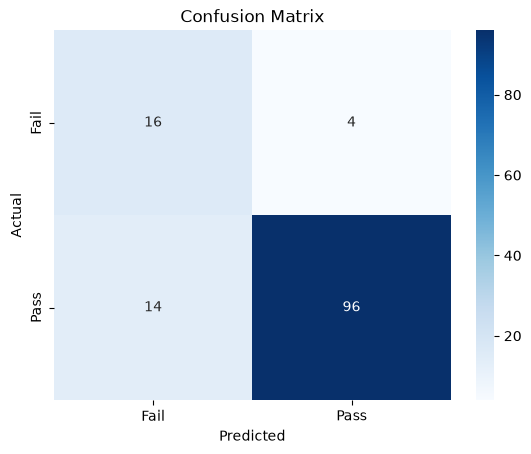

In [25]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

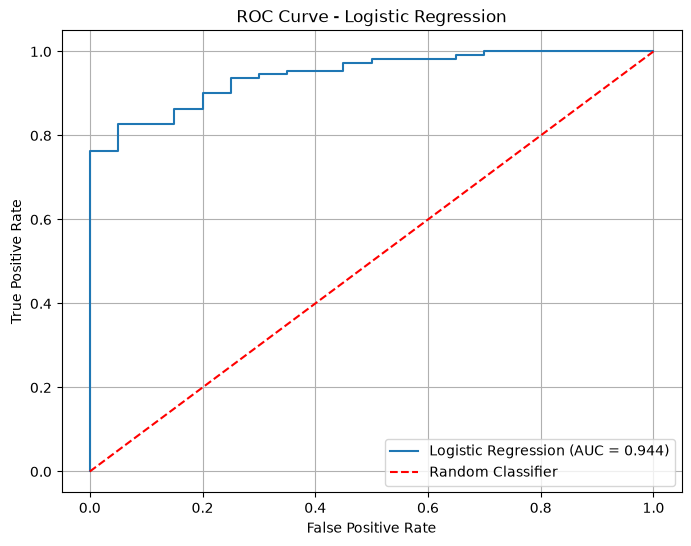

ROC-AUC Score: 0.9440909090909091


In [30]:
from sklearn.metrics import roc_curve

y_probability = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_probability)
auc = roc_auc_score(y_test, y_probability)


plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.3f})')


plt.plot([0, 1], [0, 1], linestyle='--', color='red',
         label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')

plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", auc)

In [26]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")
precision = precision_score(y_test, y_pred)

print("Precision:", precision)
recall = recall_score(y_test, y_pred)

print("Recall:", recall)
f1 = f1_score(y_test, y_pred)

print("F1 Score:", f1)
print(classification_report(
    y_test,
    y_pred,
    target_names=['Fail', 'Pass']
))
auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", auc)

Accuracy: 0.8615384615384616
Accuracy percentage: 86.15384615384616 %
Precision: 0.96
Recall: 0.8727272727272727
F1 Score: 0.9142857142857143
              precision    recall  f1-score   support

        Fail       0.53      0.80      0.64        20
        Pass       0.96      0.87      0.91       110

    accuracy                           0.86       130
   macro avg       0.75      0.84      0.78       130
weighted avg       0.89      0.86      0.87       130

ROC-AUC Score: 0.9440909090909091
